# MACHINE LEARNING FOR BUSINESS APPLICATIONS

## ASSIGNMENT 2
### Build & Deploy a Business Analytics Model

**Project Title:** Stock Market Risk Prediction Using Machine Learning  
**Subject:** Machine Learning for Business Applications  
**Assignment:** 2  
**Section:** FBA-2  
**Dataset:** NSE Historical Stock Market Data  

**Group Members:**
1. Bheemsetty Gokul — 25MBAR0407
2. Yashas K S — 25MBAR0261
3. Deepthi B Doshi — 25MBAR0483
4. Keshav S — 25MBAR0333
5. Phaneendra S — 25MBAR0087


## 1. Installing Required Libraries

Before beginning the analysis, we need to install the Python libraries required for downloading, processing, analysing and modelling stock market data.

The following libraries will be used throughout the project:

- yfinance: To retrieve historical stock market data from Yahoo Finance.
- Pandas: To organise and manipulate datasets.
- NumPy: To perform numerical calculations.
- Matplotlib: To create data visualisations.
- Seaborn: To create statistical charts and heatmaps.
- Scikit-learn: To build and evaluate machine learning models.
- Joblib: To save the trained machine learning model.


In [1]:

!pip install -q yfinance pandas numpy matplotlib seaborn scikit-learn joblib



## 2. Importing Required Libraries

After installing the libraries, we import them into our Python environment.

Importing allows us to use the functions and features provided by each library throughout the project.


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!



## 3. Selecting NSE-Listed Companies

For this project, we have selected 15 companies listed on the National Stock Exchange (NSE) of India.

The companies belong to different business sectors, allowing us to study and compare historical stock market behaviour across different industries.

We will use their Yahoo Finance ticker symbols to retrieve five years of daily historical stock market data.


In [3]:
tickers = [
    "RELIANCE.NS",
    "HDFCBANK.NS",
    "INFY.NS",
    "TCS.NS",
    "ITC.NS",
    "LT.NS",
    "BHARTIARTL.NS",
    "ICICIBANK.NS",
    "HINDUNILVR.NS",
    "SBIN.NS",
    "AXISBANK.NS",
    "MARUTI.NS",
    "SUNPHARMA.NS",
    "TITAN.NS",
    "POWERGRID.NS"
]

print("Total selected companies:", len(tickers))

for ticker in tickers:
    print(ticker)

Total selected companies: 15
RELIANCE.NS
HDFCBANK.NS
INFY.NS
TCS.NS
ITC.NS
LT.NS
BHARTIARTL.NS
ICICIBANK.NS
HINDUNILVR.NS
SBIN.NS
AXISBANK.NS
MARUTI.NS
SUNPHARMA.NS
TITAN.NS
POWERGRID.NS



## 4. Downloading Historical Stock Market Data

We use the yfinance Python library to retrieve five years of daily historical stock market data from Yahoo Finance.

For each selected company, the dataset provides:

- Open: Opening stock price.
- High: Highest stock price during the trading session.
- Low: Lowest stock price during the trading session.
- Close: Adjusted closing stock price because auto_adjust is enabled.
- Volume: Number of shares traded.

The data for all selected companies will subsequently be combined into one dataset.

Each observation represents one company on one trading date.


In [4]:
stock_data = []
failed_tickers = []

for ticker in tickers:

    print("Downloading:", ticker)

    try:
        data = yf.download(
            ticker,
            period="5y",
            interval="1d",
            auto_adjust=True,
            progress=False
        )

        if not data.empty:

            # Handle different yfinance column formats
            if isinstance(data.columns, pd.MultiIndex):
                data.columns = data.columns.get_level_values(0)

            data = data.reset_index()

            # Identify the company for each observation
            data["Stock"] = ticker

            stock_data.append(data)

            print("Successfully downloaded:", ticker)

        else:
            print("No data available:", ticker)
            failed_tickers.append(ticker)

    except Exception as e:

        print("Download failed:", ticker, e)
        failed_tickers.append(ticker)


print("\nDOWNLOAD SUMMARY")
print("-------------------------")
print("Selected companies:", len(tickers))
print("Successfully downloaded:", len(stock_data))
print("Failed companies:", len(failed_tickers))

if failed_tickers:
    print("Failed ticker symbols:", failed_tickers)

Downloading: RELIANCE.NS
Successfully downloaded: RELIANCE.NS
Downloading: HDFCBANK.NS
Successfully downloaded: HDFCBANK.NS
Downloading: INFY.NS
Successfully downloaded: INFY.NS
Downloading: TCS.NS
Successfully downloaded: TCS.NS
Downloading: ITC.NS
Successfully downloaded: ITC.NS
Downloading: LT.NS
Successfully downloaded: LT.NS
Downloading: BHARTIARTL.NS
Successfully downloaded: BHARTIARTL.NS
Downloading: ICICIBANK.NS
Successfully downloaded: ICICIBANK.NS
Downloading: HINDUNILVR.NS
Successfully downloaded: HINDUNILVR.NS
Downloading: SBIN.NS
Successfully downloaded: SBIN.NS
Downloading: AXISBANK.NS
Successfully downloaded: AXISBANK.NS
Downloading: MARUTI.NS
Successfully downloaded: MARUTI.NS
Downloading: SUNPHARMA.NS
Successfully downloaded: SUNPHARMA.NS
Downloading: TITAN.NS
Successfully downloaded: TITAN.NS
Downloading: POWERGRID.NS
Successfully downloaded: POWERGRID.NS

DOWNLOAD SUMMARY
-------------------------
Selected companies: 15
Successfully downloaded: 15
Failed companies: 0


## 5. Combining the Stock Market Datasets

After downloading historical data for the selected companies, we combine the individual datasets into one consolidated dataset using Pandas.

This creates a single dataset containing observations from all successfully downloaded companies.

Combining the datasets makes it easier to perform data cleaning, exploratory data analysis and machine learning.


In [5]:
if stock_data:

    final_data = pd.concat(
        stock_data,
        ignore_index=True
    )

    print("DATASET CREATED SUCCESSFULLY")

    print("Total observations:", len(final_data))
    print("Total columns:", len(final_data.columns))
    print("Total companies:", final_data["Stock"].nunique())

else:

    raise ValueError("No stock data was downloaded. Check the download errors.")

DATASET CREATED SUCCESSFULLY
Total observations: 18540
Total columns: 7
Total companies: 15



## 6. Understanding the Downloaded Dataset

Before performing data cleaning, we need to understand the structure and characteristics of the downloaded dataset.

We use Pandas functions to examine the first few records, dataset dimensions, column names, data types, numerical summaries and observations available for each company.

This initial inspection helps us understand the dataset before making any changes.


In [6]:
display(final_data.head())

Price,Date,Close,High,Low,Open,Volume,Stock
0,2021-11-12,1174.461304,1177.020358,1158.110957,1160.783223,8712341,RELIANCE.NS
1,2021-11-15,1167.531860,1178.583082,1163.999068,1177.586582,4803269,RELIANCE.NS
2,2021-11-16,1140.402100,1166.263636,1130.030266,1164.927503,11337581,RELIANCE.NS
3,2021-11-17,1115.989868,1131.819326,1114.631093,1131.819326,10202029,RELIANCE.NS
4,2021-11-18,1120.201782,1127.312650,1109.671454,1114.177982,8505625,RELIANCE.NS


In [7]:
print("Dataset Shape:", final_data.shape)

print("Number of Rows:", final_data.shape[0])
print("Number of Columns:", final_data.shape[1])

Dataset Shape: (18540, 7)
Number of Rows: 18540
Number of Columns: 7


In [8]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18540 entries, 0 to 18539
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    18540 non-null  datetime64[ns]
 1   Close   18540 non-null  float64       
 2   High    18540 non-null  float64       
 3   Low     18540 non-null  float64       
 4   Open    18540 non-null  float64       
 5   Volume  18540 non-null  int64         
 6   Stock   18540 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 1014.0+ KB


In [9]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18540 entries, 0 to 18539
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    18540 non-null  datetime64[ns]
 1   Close   18540 non-null  float64       
 2   High    18540 non-null  float64       
 3   Low     18540 non-null  float64       
 4   Open    18540 non-null  float64       
 5   Volume  18540 non-null  int64         
 6   Stock   18540 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 1014.0+ KB


In [10]:
display(final_data.describe())

Price,Date,Close,High,Low,Open,Volume
count,18540,18540.000000,18540.000000,18540.000000,18540.000000,1.854000e+04
mean,2024-05-12 08:39:36.699029248,2139.994397,2160.871926,2119.168814,2140.818758,9.064439e+06
min,2021-11-12 00:00:00,105.641121,106.627874,104.654368,105.757207,0.000000e+00
25%,2023-02-07 18:00:00,781.604828,789.091705,774.126976,781.440675,1.780673e+06
50%,2024-05-15 12:00:00,1299.144653,1311.312617,1286.107225,1298.942070,6.132062e+06
75%,2025-08-11 06:00:00,2391.373840,2412.925309,2369.517674,2390.710507,1.230017e+07
max,2026-11-12 00:00:00,17120.062500,17197.286033,16971.553977,17058.679159,4.453421e+08
std,NaN,2641.838488,2668.001736,2615.574282,2643.489831,1.212015e+07


In [11]:
company_counts = final_data.groupby("Stock").size()

display(company_counts)

print("\nTotal companies:", final_data["Stock"].nunique())

,0
Stock,
AXISBANK.NS,1236
BHARTIARTL.NS,1236
HDFCBANK.NS,1236
HINDUNILVR.NS,1236
ICICIBANK.NS,1236
INFY.NS,1236
ITC.NS,1236
LT.NS,1236
MARUTI.NS,1236



Total companies: 15


In [12]:
print("Starting Date:", final_data["Date"].min())

print("Ending Date:", final_data["Date"].max())

Starting Date: 2021-11-12 00:00:00
Ending Date: 2026-11-12 00:00:00



## 7. Saving the Original Dataset

After downloading and inspecting the stock market data, we save the consolidated dataset as a CSV file.

This preserves the original downloaded data so that it can be reused during data preparation, exploratory data analysis and machine learning.

The original dataset is kept separate from the cleaned dataset to maintain a clear record of the data preparation process.


In [13]:
final_data.to_csv(
    "nse_stock_historical_data_raw.csv",
    index=False
)

print("Raw dataset saved successfully!")

Raw dataset saved successfully!



## 8. Checking Missing Values

Missing values occur when a dataset does not contain information for a particular observation or variable.

We examine each column to identify the number and percentage of missing values. This helps determine whether any data preparation is required.


In [14]:
missing_values = final_data.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(final_data)) * 100
})

display(missing_summary)

,Missing Values,Missing Percentage
Price,,
Date,0,0.0
Close,0,0.0
High,0,0.0
Low,0,0.0
Open,0,0.0
Volume,0,0.0
Stock,0,0.0



## 9. Checking Duplicate Records

Duplicate records occur when the same observation appears more than once.

We check for duplicate rows to ensure that repeated observations do not unnecessarily affect our analysis.


In [15]:
print("Total duplicate rows:", final_data.duplicated().sum())

print(
    "Duplicate Stock-Date combinations:",
    final_data.duplicated(subset=["Stock", "Date"]).sum()
)

Total duplicate rows: 0
Duplicate Stock-Date combinations: 0



## 10. Checking Data Types

We examine the data types of each variable to ensure that numerical values, dates and categorical identifiers are represented appropriately.

Correct data types are important for performing calculations and preparing the dataset for machine learning.


In [16]:
print(final_data.dtypes)

Price
Date      datetime64[ns]
Close            float64
High             float64
Low              float64
Open             float64
Volume             int64
Stock             object
dtype: object



## 11. Investigating Zero Trading Volume

Trading volume represents the number of shares traded during a particular trading session.

We investigate records with zero trading volume to understand whether they represent unusual observations or data quality issues.


In [17]:
zero_volume = final_data[final_data["Volume"] == 0]

print("Records with zero trading volume:", len(zero_volume))

display(zero_volume.head(10))

Records with zero trading volume: 29


Price,Date,Close,High,Low,Open,Volume,Stock
827,2025-03-18,1228.242920,1228.242920,1228.242920,1228.242920,0,RELIANCE.NS
1033,2026-01-15,1452.086182,1452.086182,1452.086182,1452.086182,0,RELIANCE.NS
2063,2025-03-18,830.065613,830.065613,830.065613,830.065613,0,HDFCBANK.NS
2269,2026-01-15,910.392639,910.392639,910.392639,910.392639,0,HDFCBANK.NS
3299,2025-03-18,1477.782959,1477.782959,1477.782959,1477.782959,0,INFY.NS
3505,2026-01-15,1530.846802,1530.846802,1530.846802,1530.846802,0,INFY.NS
4535,2025-03-18,3299.900391,3299.900391,3299.900391,3299.900391,0,TCS.NS
4741,2026-01-15,3060.415527,3060.415527,3060.415527,3060.415527,0,TCS.NS
5977,2026-01-15,319.182861,319.182861,319.182861,319.182861,0,ITC.NS
7007,2025-03-18,3113.714111,3113.714111,3113.714111,3113.714111,0,LT.NS



## 12. Checking the Latest Available Trading Dates

We examine the latest available observations for each company to identify differences in data coverage and check whether the latest records require further investigation.


In [18]:
latest_dates = final_data.groupby("Stock")["Date"].max()

display(latest_dates)

,Date
Stock,
AXISBANK.NS,2026-11-12
BHARTIARTL.NS,2026-11-12
HDFCBANK.NS,2026-11-12
HINDUNILVR.NS,2026-11-12
ICICIBANK.NS,2026-11-12
INFY.NS,2026-11-12
ITC.NS,2026-11-12
LT.NS,2026-11-12
MARUTI.NS,2026-11-12



## 13. Investigating Zero-Volume Observations

We further investigate observations with zero trading volume by examining their distribution across companies and trading dates.

This helps identify whether these records are isolated data issues or occur across multiple companies on common dates.


In [19]:
zero_volume = final_data[final_data["Volume"] == 0].copy()

print("Total zero-volume records:", len(zero_volume))

print("\nZero-volume records by company:")
display(zero_volume.groupby("Stock").size())

print("\nDates with zero-volume records:")
display(zero_volume.groupby("Date").size())

print("\nDo OHLC prices remain identical?")
zero_volume["OHLC_Identical"] = (
    (zero_volume["Open"] == zero_volume["High"]) &
    (zero_volume["High"] == zero_volume["Low"]) &
    (zero_volume["Low"] == zero_volume["Close"])
)

display(zero_volume[[
    "Date", "Stock", "Open", "High", "Low", "Close",
    "Volume", "OHLC_Identical"
]].head(35))

Total zero-volume records: 29

Zero-volume records by company:


,0
Stock,
AXISBANK.NS,2
BHARTIARTL.NS,2
HDFCBANK.NS,2
HINDUNILVR.NS,2
ICICIBANK.NS,2
INFY.NS,2
ITC.NS,1
LT.NS,2
MARUTI.NS,2



Dates with zero-volume records:


,0
Date,
2025-03-18,14
2026-01-15,15



Do OHLC prices remain identical?


Price,Date,Stock,Open,High,Low,Close,Volume,OHLC_Identical
827,2025-03-18,RELIANCE.NS,1228.242920,1228.242920,1228.242920,1228.242920,0,True
1033,2026-01-15,RELIANCE.NS,1452.086182,1452.086182,1452.086182,1452.086182,0,True
2063,2025-03-18,HDFCBANK.NS,830.065613,830.065613,830.065613,830.065613,0,True
2269,2026-01-15,HDFCBANK.NS,910.392639,910.392639,910.392639,910.392639,0,True
3299,2025-03-18,INFY.NS,1477.782959,1477.782959,1477.782959,1477.782959,0,True
3505,2026-01-15,INFY.NS,1530.846802,1530.846802,1530.846802,1530.846802,0,True
4535,2025-03-18,TCS.NS,3299.900391,3299.900391,3299.900391,3299.900391,0,True
4741,2026-01-15,TCS.NS,3060.415527,3060.415527,3060.415527,3060.415527,0,True
5977,2026-01-15,ITC.NS,319.182861,319.182861,319.182861,319.182861,0,True
7007,2025-03-18,LT.NS,3113.714111,3113.714111,3113.714111,3113.714111,0,True



## 14. Handling Zero-Volume Observations

During data quality assessment, 29 observations were identified with zero trading volume. These observations also had identical Open, High, Low and Close prices.

Since these records do not reflect normal trading activity, they were excluded from the cleaned working dataset.

The original raw dataset was preserved separately to maintain data integrity.


In [20]:
# Create a separate working copy
cleaned_data = final_data.copy()

# Remove observations with zero trading volume
cleaned_data = cleaned_data[cleaned_data["Volume"] > 0].copy()

# Reset the index
cleaned_data.reset_index(drop=True, inplace=True)

print("Original dataset rows:", len(final_data))
print("Cleaned dataset rows:", len(cleaned_data))
print("Rows removed:", len(final_data) - len(cleaned_data))
print("Remaining companies:", cleaned_data["Stock"].nunique())

Original dataset rows: 18540
Cleaned dataset rows: 18511
Rows removed: 29
Remaining companies: 15



## 15. Verifying the Cleaned Dataset

After handling the zero-volume observations, we verify the cleaned dataset to ensure that no zero-volume records remain and that the dataset still contains all 15 selected companies.

We also recheck missing values and duplicate records to confirm the quality of the prepared data.


In [21]:
print("Cleaned Dataset Shape:", cleaned_data.shape)

print("\nMissing Values:")
display(cleaned_data.isnull().sum())

print("\nDuplicate Rows:", cleaned_data.duplicated().sum())

print(
    "\nDuplicate Stock-Date Records:",
    cleaned_data.duplicated(subset=["Stock", "Date"]).sum()
)

print(
    "\nRemaining Zero-Volume Records:",
    (cleaned_data["Volume"] == 0).sum()
)

print("\nCompanies Remaining:", cleaned_data["Stock"].nunique())

Cleaned Dataset Shape: (18511, 7)

Missing Values:


,0
Price,
Date,0
Close,0
High,0
Low,0
Open,0
Volume,0
Stock,0



Duplicate Rows: 0

Duplicate Stock-Date Records: 0

Remaining Zero-Volume Records: 0

Companies Remaining: 15



## 16. Saving the Cleaned Dataset

The cleaned dataset is saved separately in CSV format.

This version will be used for further feature engineering, exploratory data analysis and machine learning.


In [22]:
cleaned_data.to_csv(
    "nse_stock_historical_data_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!



## 17. Preparing the Dataset for Feature Engineering

Before calculating financial indicators, we arrange the dataset in chronological order for each company.

This is important because stock market indicators such as daily returns, moving averages and volatility depend on the sequence of trading observations.


In [23]:
cleaned_data = cleaned_data.sort_values(
    by=["Stock", "Date"]
).reset_index(drop=True)

display(cleaned_data.head())

Price,Date,Close,High,Low,Open,Volume,Stock
0,2021-11-12,732.424561,739.141313,729.887133,739.141313,9372897,AXISBANK.NS
1,2021-11-15,729.638428,740.335479,724.414286,734.365032,12849161,AXISBANK.NS
2,2021-11-16,722.573364,729.688110,717.747217,729.638369,8978763,AXISBANK.NS
3,2021-11-17,708.841431,721.329667,703.269037,717.448851,18083445,AXISBANK.NS
4,2021-11-18,702.870911,712.473405,698.442877,711.478330,13458109,AXISBANK.NS



## 18. Calculating Daily Stock Returns

Daily returns measure the percentage change in a stock's closing price compared with its previous trading day's closing price.

Daily returns help us understand how much a stock's price increases or decreases from one trading session to the next.

This variable will be used to calculate historical volatility and other financial indicators.


In [24]:
cleaned_data["Daily_Return"] = (
    cleaned_data.groupby("Stock")["Close"]
    .pct_change()
)

display(
    cleaned_data[[
        "Date", "Stock", "Close", "Daily_Return"
    ]].head(15)
)

Price,Date,Stock,Close,Daily_Return
0,2021-11-12,AXISBANK.NS,732.424561,NaN
1,2021-11-15,AXISBANK.NS,729.638428,-0.003804
2,2021-11-16,AXISBANK.NS,722.573364,-0.009683
3,2021-11-17,AXISBANK.NS,708.841431,-0.019004
4,2021-11-18,AXISBANK.NS,702.870911,-0.008423
5,2021-11-22,AXISBANK.NS,683.019104,-0.028244
6,2021-11-23,AXISBANK.NS,682.272949,-0.001092
7,2021-11-24,AXISBANK.NS,681.775330,-0.000729
8,2021-11-25,AXISBANK.NS,676.551270,-0.007662
9,2021-11-26,AXISBANK.NS,658.490601,-0.026695



## 19. Examining Daily Returns

After calculating daily returns, we examine their statistical distribution and check for missing values.

This helps us understand the magnitude of daily stock price movements and identify any unusual return observations that may require further investigation.


In [25]:
print("Daily Return Summary:")
display(cleaned_data["Daily_Return"].describe())

print(
    "\nMissing Daily Returns:",
    cleaned_data["Daily_Return"].isnull().sum()
)

print("\nSample Daily Returns:")
display(
    cleaned_data[[
        "Date", "Stock", "Close", "Daily_Return"
    ]].head(20)
)

Daily Return Summary:


,Daily_Return
count,18496.000000
mean,0.000494
std,0.014351
min,-0.144040
25%,-0.007337
50%,0.000243
75%,0.007989
max,0.115976



Missing Daily Returns: 15

Sample Daily Returns:


Price,Date,Stock,Close,Daily_Return
0,2021-11-12,AXISBANK.NS,732.424561,NaN
1,2021-11-15,AXISBANK.NS,729.638428,-0.003804
2,2021-11-16,AXISBANK.NS,722.573364,-0.009683
3,2021-11-17,AXISBANK.NS,708.841431,-0.019004
4,2021-11-18,AXISBANK.NS,702.870911,-0.008423
5,2021-11-22,AXISBANK.NS,683.019104,-0.028244
6,2021-11-23,AXISBANK.NS,682.272949,-0.001092
7,2021-11-24,AXISBANK.NS,681.775330,-0.000729
8,2021-11-25,AXISBANK.NS,676.551270,-0.007662
9,2021-11-26,AXISBANK.NS,658.490601,-0.026695



## 20. Calculating Historical Stock Volatility

Volatility measures the degree of variation in stock returns over a period of time.

In this project, rolling standard deviation of daily returns is used to measure historical stock price fluctuations.

We calculate 20-day and 60-day rolling volatility to understand short-term and longer-term market behaviour.

The volatility values are annualised using the square root of 252 trading days, which is commonly used as an approximate number of trading days in a year.


In [26]:
cleaned_data["Volatility_20"] = (
    cleaned_data.groupby("Stock")["Daily_Return"]
    .transform(lambda x: x.rolling(20).std() * np.sqrt(252))
)

cleaned_data["Volatility_60"] = (
    cleaned_data.groupby("Stock")["Daily_Return"]
    .transform(lambda x: x.rolling(60).std() * np.sqrt(252))
)

display(cleaned_data[[
    "Date",
    "Stock",
    "Daily_Return",
    "Volatility_20",
    "Volatility_60"
]].head(30))

Price,Date,Stock,Daily_Return,Volatility_20,Volatility_60
0,2021-11-12,AXISBANK.NS,NaN,NaN,NaN
1,2021-11-15,AXISBANK.NS,-0.003804,NaN,NaN
2,2021-11-16,AXISBANK.NS,-0.009683,NaN,NaN
3,2021-11-17,AXISBANK.NS,-0.019004,NaN,NaN
4,2021-11-18,AXISBANK.NS,-0.008423,NaN,NaN
5,2021-11-22,AXISBANK.NS,-0.028244,NaN,NaN
6,2021-11-23,AXISBANK.NS,-0.001092,NaN,NaN
7,2021-11-24,AXISBANK.NS,-0.000729,NaN,NaN
8,2021-11-25,AXISBANK.NS,-0.007662,NaN,NaN
9,2021-11-26,AXISBANK.NS,-0.026695,NaN,NaN



## 21. Calculating Moving Averages

A moving average represents the average closing price of a stock over a specified number of previous trading days.

The 20-day moving average captures relatively short-term price behaviour, while the 60-day moving average represents a longer-term trend.

These indicators help identify changes in stock price trends and can be used as predictor variables in the machine learning model.


In [27]:
cleaned_data["MA_20"] = (
    cleaned_data.groupby("Stock")["Close"]
    .transform(lambda x: x.rolling(20).mean())
)

cleaned_data["MA_60"] = (
    cleaned_data.groupby("Stock")["Close"]
    .transform(lambda x: x.rolling(60).mean())
)

display(cleaned_data[[
    "Date",
    "Stock",
    "Close",
    "MA_20",
    "MA_60"
]].head(30))

Price,Date,Stock,Close,MA_20,MA_60
0,2021-11-12,AXISBANK.NS,732.424561,NaN,NaN
1,2021-11-15,AXISBANK.NS,729.638428,NaN,NaN
2,2021-11-16,AXISBANK.NS,722.573364,NaN,NaN
3,2021-11-17,AXISBANK.NS,708.841431,NaN,NaN
4,2021-11-18,AXISBANK.NS,702.870911,NaN,NaN
5,2021-11-22,AXISBANK.NS,683.019104,NaN,NaN
6,2021-11-23,AXISBANK.NS,682.272949,NaN,NaN
7,2021-11-24,AXISBANK.NS,681.775330,NaN,NaN
8,2021-11-25,AXISBANK.NS,676.551270,NaN,NaN
9,2021-11-26,AXISBANK.NS,658.490601,NaN,NaN



## 22. Calculating Trading Volume Change

Trading volume represents the number of shares traded during a trading session.

Volume change measures the percentage variation in trading activity compared with the previous trading day.

This feature helps examine whether changes in trading activity are associated with stock price movements and volatility.


In [28]:
cleaned_data["Volume_Change"] = (
    cleaned_data.groupby("Stock")["Volume"]
    .pct_change()
)

display(cleaned_data[[
    "Date",
    "Stock",
    "Volume",
    "Volume_Change"
]].head(20))

Price,Date,Stock,Volume,Volume_Change
0,2021-11-12,AXISBANK.NS,9372897,NaN
1,2021-11-15,AXISBANK.NS,12849161,0.370885
2,2021-11-16,AXISBANK.NS,8978763,-0.301218
3,2021-11-17,AXISBANK.NS,18083445,1.014024
4,2021-11-18,AXISBANK.NS,13458109,-0.255777
5,2021-11-22,AXISBANK.NS,16741079,0.243940
6,2021-11-23,AXISBANK.NS,16575348,-0.009900
7,2021-11-24,AXISBANK.NS,11463429,-0.308405
8,2021-11-25,AXISBANK.NS,9760486,-0.148554
9,2021-11-26,AXISBANK.NS,10252753,0.050435


In [29]:
feature_columns = [
    "Daily_Return",
    "Volatility_20",
    "Volatility_60",
    "MA_20",
    "MA_60",
    "Volume_Change"
]

print("Engineered Feature Summary:")
display(cleaned_data[feature_columns].describe())

print("\nMissing Values in Engineered Features:")
display(cleaned_data[feature_columns].isnull().sum())

Engineered Feature Summary:


Price,Daily_Return,Volatility_20,Volatility_60,MA_20,MA_60,Volume_Change
count,18496.000000,18211.000000,17611.000000,18226.000000,17626.000000,18496.000000
mean,0.000494,0.215102,0.219167,2141.458238,2147.670303,0.167655
std,0.014351,0.072888,0.055603,2642.579700,2648.376877,1.151042
min,-0.144040,0.054756,0.100860,116.097851,121.787152,-0.972136
25%,-0.007337,0.162847,0.179334,779.228439,781.705444,-0.267694
50%,0.000243,0.202655,0.209579,1296.333774,1302.959637,-0.011568
75%,0.007989,0.251190,0.252432,2392.518439,2398.949837,0.349080
max,0.115976,0.649486,0.441643,16484.990234,16067.070866,51.803822



Missing Values in Engineered Features:


,0
Price,
Daily_Return,15
Volatility_20,300
Volatility_60,900
MA_20,285
MA_60,885
Volume_Change,15



## 23. Creating the Future Volatility Target

The objective of this project is to predict future stock market risk using historical stock market information.

For this purpose, we calculate the annualised volatility of daily stock returns over the following 20 trading days.

The calculation is performed separately for each company to ensure that observations from different stocks are not mixed.

The future volatility value will later be converted into three risk categories: Low, Medium and High.

Only information from the future 20 trading days is used to calculate the target. Predictor variables will contain information available on or before the prediction date.


In [30]:
# Sort observations chronologically within each company
cleaned_data = cleaned_data.sort_values(
    ["Stock", "Date"]
).reset_index(drop=True)

# Calculate future 20-day annualised volatility
cleaned_data["Future_Volatility_20"] = (
    cleaned_data.groupby("Stock")["Daily_Return"]
    .transform(
        lambda x: (
            x.shift(-1)
             .rolling(window=20, min_periods=20)
             .std()
             .shift(-19)
             * np.sqrt(252)
        )
    )
)

display(cleaned_data[[
    "Date",
    "Stock",
    "Daily_Return",
    "Future_Volatility_20"
]].head(30))

Price,Date,Stock,Daily_Return,Future_Volatility_20
0,2021-11-12,AXISBANK.NS,NaN,0.283893
1,2021-11-15,AXISBANK.NS,-0.003804,0.286885
2,2021-11-16,AXISBANK.NS,-0.009683,0.285434
3,2021-11-17,AXISBANK.NS,-0.019004,0.277601
4,2021-11-18,AXISBANK.NS,-0.008423,0.295209
5,2021-11-22,AXISBANK.NS,-0.028244,0.287500
6,2021-11-23,AXISBANK.NS,-0.001092,0.290580
7,2021-11-24,AXISBANK.NS,-0.000729,0.291513
8,2021-11-25,AXISBANK.NS,-0.007662,0.295147
9,2021-11-26,AXISBANK.NS,-0.026695,0.285037



## 24. Examining Future Volatility

After calculating future volatility, we examine its statistical distribution and missing values.

The final 20 observations of each company will not have a complete future 20-day period. These observations will therefore have missing target values and will not be used for supervised model training.


In [31]:
print("Future Volatility Summary:")
display(cleaned_data["Future_Volatility_20"].describe())

print(
    "\nMissing Future Volatility Values:",
    cleaned_data["Future_Volatility_20"].isnull().sum()
)

print("\nSample Future Volatility:")
display(cleaned_data[[
    "Date",
    "Stock",
    "Daily_Return",
    "Future_Volatility_20"
]].head(30))

Future Volatility Summary:


,Future_Volatility_20
count,18211.000000
mean,0.215102
std,0.072888
min,0.054756
25%,0.162847
50%,0.202655
75%,0.251190
max,0.649486



Missing Future Volatility Values: 300

Sample Future Volatility:


Price,Date,Stock,Daily_Return,Future_Volatility_20
0,2021-11-12,AXISBANK.NS,NaN,0.283893
1,2021-11-15,AXISBANK.NS,-0.003804,0.286885
2,2021-11-16,AXISBANK.NS,-0.009683,0.285434
3,2021-11-17,AXISBANK.NS,-0.019004,0.277601
4,2021-11-18,AXISBANK.NS,-0.008423,0.295209
5,2021-11-22,AXISBANK.NS,-0.028244,0.287500
6,2021-11-23,AXISBANK.NS,-0.001092,0.290580
7,2021-11-24,AXISBANK.NS,-0.000729,0.291513
8,2021-11-25,AXISBANK.NS,-0.007662,0.295147
9,2021-11-26,AXISBANK.NS,-0.026695,0.285037



## 25. Preparing the Dataset for Risk Classification

We prepare the modelling dataset by selecting observations that contain complete historical financial indicators and a valid future volatility target.

The dataset will be arranged chronologically so that the training period precedes the testing period.

Risk categories will be defined using volatility thresholds calculated from the training data only. This prevents information from the testing period from influencing the classification thresholds.


In [32]:
# Select the historical predictor variables
feature_columns = [
    "Daily_Return",
    "Volatility_20",
    "Volatility_60",
    "MA_20",
    "MA_60",
    "Volume_Change"
]

# Keep rows with complete predictors and future target
model_data = cleaned_data.dropna(
    subset=feature_columns + ["Future_Volatility_20"]
).copy()

# Sort chronologically
model_data = model_data.sort_values(
    ["Date", "Stock"]
).reset_index(drop=True)

print("Modelling dataset shape:", model_data.shape)
print("Companies:", model_data["Stock"].nunique())
print("Missing values:")
display(model_data[feature_columns + ["Future_Volatility_20"]].isnull().sum())

Modelling dataset shape: (17311, 14)
Companies: 15
Missing values:


,0
Price,
Daily_Return,0
Volatility_20,0
Volatility_60,0
MA_20,0
MA_60,0
Volume_Change,0
Future_Volatility_20,0


In [36]:
# Get all unique trading dates
unique_dates = sorted(model_data["Date"].unique())

# Original 80/20 chronological split
split_position = int(len(unique_dates) * 0.80)

# Keep a 20-trading-day gap before testing
training_dates = unique_dates[:split_position - 20]
testing_dates = unique_dates[split_position:]

# Create revised training and testing datasets
train_data = model_data[
    model_data["Date"].isin(training_dates)
].copy()

test_data = model_data[
    model_data["Date"].isin(testing_dates)
].copy()

# Calculate thresholds using training data only
lower_threshold = train_data["Future_Volatility_20"].quantile(0.33)
upper_threshold = train_data["Future_Volatility_20"].quantile(0.67)

# Assign risk categories using the training thresholds
def assign_risk_category(volatility, lower, upper):
    if volatility <= lower:
        return "Low"
    elif volatility <= upper:
        return "Medium"
    else:
        return "High"

train_data["Risk_Category"] = train_data["Future_Volatility_20"].apply(
    lambda x: assign_risk_category(x, lower_threshold, upper_threshold)
)

test_data["Risk_Category"] = test_data["Future_Volatility_20"].apply(
    lambda x: assign_risk_category(x, lower_threshold, upper_threshold)
)

# Display revised results
print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining date range:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting date range:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

print("\n20-trading-day gap applied.")

print("\nNew thresholds:")
print("Low/Medium:", lower_threshold)
print("Medium/High:", upper_threshold)

print("\nTraining risk distribution:")
display(train_data["Risk_Category"].value_counts())

print("\nTesting risk distribution:")
display(test_data["Risk_Category"].value_counts())

Training observations: 13546
Testing observations: 3465

Training date range:
2022-02-08 00:00:00 to 2025-10-06 00:00:00

Testing date range:
2025-11-06 00:00:00 to 2026-10-13 00:00:00

20-trading-day gap applied.

New thresholds:
Low/Medium: 0.17185559284877716
Medium/High: 0.2281293458939376

Training risk distribution:


,count
Risk_Category,
Medium,4606
High,4470
Low,4470



Testing risk distribution:


,count
Risk_Category,
High,1442
Medium,1178
Low,845



## 26. Chronological Training and Testing Periods

Stock market observations are time-dependent. Therefore, a chronological split is used instead of randomly distributing observations.

The earlier 80% of dates are used for training, while the later 20% are reserved for testing.

This approach helps evaluate the model on a future period that it has not seen during training.


In [37]:
unique_dates = sorted(model_data["Date"].unique())

split_position = int(len(unique_dates) * 0.80)

training_dates = unique_dates[:split_position]
testing_dates = unique_dates[split_position:]

train_data = model_data[
    model_data["Date"].isin(training_dates)
].copy()

test_data = model_data[
    model_data["Date"].isin(testing_dates)
].copy()

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("Training date range:",
      train_data["Date"].min(), "to", train_data["Date"].max())

print("Testing date range:",
      test_data["Date"].min(), "to", test_data["Date"].max())

Training observations: 13846
Testing observations: 3465
Training date range: 2022-02-08 00:00:00 to 2025-11-04 00:00:00
Testing date range: 2025-11-06 00:00:00 to 2026-10-13 00:00:00



## 27. Establishing Risk Classification Thresholds

The 33rd and 67th percentiles of future volatility in the training dataset are used to establish risk classification thresholds.

Observations below or equal to the lower threshold are classified as Low Risk. Observations between the two thresholds are classified as Medium Risk. Observations above the upper threshold are classified as High Risk.

The same thresholds are subsequently applied to the testing dataset.


In [38]:
lower_threshold = train_data["Future_Volatility_20"].quantile(0.33)
upper_threshold = train_data["Future_Volatility_20"].quantile(0.67)

print("Low/Medium threshold:", lower_threshold)
print("Medium/High threshold:", upper_threshold)

Low/Medium threshold: 0.17075226059622411
Medium/High threshold: 0.22706822457992684


In [39]:
def assign_risk_category(volatility, lower, upper):

    if volatility <= lower:
        return "Low"

    elif volatility <= upper:
        return "Medium"

    else:
        return "High"


train_data["Risk_Category"] = train_data[
    "Future_Volatility_20"
].apply(
    lambda x: assign_risk_category(
        x, lower_threshold, upper_threshold
    )
)

test_data["Risk_Category"] = test_data[
    "Future_Volatility_20"
].apply(
    lambda x: assign_risk_category(
        x, lower_threshold, upper_threshold
    )
)

print("Training risk distribution:")
display(train_data["Risk_Category"].value_counts())

print("\nTesting risk distribution:")
display(test_data["Risk_Category"].value_counts())

Training risk distribution:


,count
Risk_Category,
Medium,4708
High,4569
Low,4569



Testing risk distribution:


,count
Risk_Category,
High,1468
Medium,1179
Low,818


In [40]:
# Calculate relative moving-average features
model_data["Price_to_MA20"] = (
    model_data["Close"] / model_data["MA_20"]
) - 1

model_data["Price_to_MA60"] = (
    model_data["Close"] / model_data["MA_60"]
) - 1

# Define final predictor variables
feature_columns = [
    "Daily_Return",
    "Volatility_20",
    "Volatility_60",
    "Price_to_MA20",
    "Price_to_MA60",
    "Volume_Change"
]

print("Final features:")
print(feature_columns)

print("\nMissing values:")
display(model_data[feature_columns].isnull().sum())

print("\nFeature summary:")
display(model_data[feature_columns].describe())

Final features:
['Daily_Return', 'Volatility_20', 'Volatility_60', 'Price_to_MA20', 'Price_to_MA60', 'Volume_Change']

Missing values:


,0
Price,
Daily_Return,0
Volatility_20,0
Volatility_60,0
Price_to_MA20,0
Price_to_MA60,0
Volume_Change,0



Feature summary:


Price,Daily_Return,Volatility_20,Volatility_60,Price_to_MA20,Price_to_MA60,Volume_Change
count,17311.000000,17311.000000,17311.000000,17311.000000,17311.000000,17311.000000
mean,0.000417,0.213448,0.218978,0.003225,0.011304,0.169841
std,0.014184,0.073224,0.055722,0.034257,0.058793,1.176061
min,-0.144040,0.054756,0.100860,-0.187084,-0.206293,-0.972136
25%,-0.007280,0.160865,0.179002,-0.018291,-0.028236,-0.268541
50%,0.000200,0.200285,0.209520,0.003790,0.010162,-0.011007
75%,0.007824,0.249500,0.252369,0.025601,0.052284,0.352077
max,0.100133,0.649486,0.441643,0.158923,0.226255,51.803822


In [41]:
# Identify unusually large volume changes
print("Volume Change above 5:")
print((model_data["Volume_Change"] > 5).sum())

print("\nVolume Change above 10:")
print((model_data["Volume_Change"] > 10).sum())

print("\nTop 10 highest volume changes:")
display(
    model_data[
        ["Date", "Stock", "Volume", "Volume_Change"]
    ].sort_values(
        "Volume_Change", ascending=False
    ).head(10)
)

Volume Change above 5:
81

Volume Change above 10:
27

Top 10 highest volume changes:


Price,Date,Stock,Volume,Volume_Change
13720,2025-10-23,POWERGRID.NS,21031287,51.803822
10137,2024-11-04,SUNPHARMA.NS,5031861,45.766246
13714,2025-10-23,HINDUNILVR.NS,3386744,40.291685
13712,2025-10-23,BHARTIARTL.NS,8790128,35.496276
13723,2025-10-23,SUNPHARMA.NS,2687094,35.167411
15889,2026-05-29,HINDUNILVR.NS,17701621,27.711322
14437,2026-01-01,ITC.NS,282626710,27.418664
2648,2022-10-25,MARUTI.NS,727441,23.206076
12962,2025-08-08,BHARTIARTL.NS,93801105,20.975016
10126,2024-11-04,BHARTIARTL.NS,6094029,20.807927


In [44]:
# Apply signed logarithmic transformation
model_data["Log_Volume_Change"] = (
    np.sign(model_data["Volume_Change"]) *
    np.log1p(np.abs(model_data["Volume_Change"]))
)

# Compare original and transformed values
print("Original Volume Change:")
display(model_data["Volume_Change"].describe())

print("\nTransformed Volume Change:")
display(model_data["Log_Volume_Change"].describe())

Original Volume Change:


,Volume_Change
count,17311.000000
mean,0.169841
std,1.176061
min,-0.972136
25%,-0.268541
50%,-0.011007
75%,0.352077
max,51.803822



Transformed Volume Change:


,Log_Volume_Change
count,17311.000000
mean,0.071710
std,0.419297
min,-0.679117
25%,-0.237867
50%,-0.010947
75%,0.301642
max,3.966584


In [45]:
feature_columns = [
    "Daily_Return",
    "Volatility_20",
    "Volatility_60",
    "Price_to_MA20",
    "Price_to_MA60",
    "Log_Volume_Change"
]

### Preparation of Training and Testing Variables

The dataset was divided into predictor variables (X) and the target variable (y) to prepare it for machine learning.

The six predictor variables represent historical stock market information, including daily returns, historical volatility, relative moving averages and transformed trading volume changes.

The target variable, Risk_Category, represents the future stock risk classification into three categories: Low, Medium and High.

The training dataset is used to train the machine learning models, while the testing dataset is reserved to evaluate their performance on unseen observations. This separation helps assess how effectively the models can classify future stock risk.

In [48]:
# Recreate training and testing datasets
train_data = model_data[
    model_data["Date"].isin(training_dates)
].copy()

test_data = model_data[
    model_data["Date"].isin(testing_dates)
].copy()

# Recreate risk categories using training thresholds
def assign_risk_category(volatility, lower, upper):
    if volatility <= lower:
        return "Low"
    elif volatility <= upper:
        return "Medium"
    else:
        return "High"

train_data["Risk_Category"] = train_data["Future_Volatility_20"].apply(
    lambda x: assign_risk_category(x, lower_threshold, upper_threshold)
)

test_data["Risk_Category"] = test_data["Future_Volatility_20"].apply(
    lambda x: assign_risk_category(x, lower_threshold, upper_threshold)
)

# Prepare model inputs
X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

y_train = train_data["Risk_Category"]
y_test = test_data["Risk_Category"]

# Display results
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (13846, 6)
Testing feature shape: (3465, 6)
Training target shape: (13846,)
Testing target shape: (3465,)


In [49]:
print("First training date:", train_data["Date"].min())
print("Last training date:", train_data["Date"].max())

print("\nFirst testing date:", test_data["Date"].min())
print("Last testing date:", test_data["Date"].max())

print("\nTraining unique dates:", train_data["Date"].nunique())
print("Testing unique dates:", test_data["Date"].nunique())

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

First training date: 2022-02-08 00:00:00
Last training date: 2025-11-04 00:00:00

First testing date: 2025-11-06 00:00:00
Last testing date: 2026-10-13 00:00:00

Training unique dates: 924
Testing unique dates: 231

Training observations: 13846
Testing observations: 3465


The chronological split reserves the latest 20% of trading dates for testing. A 20-trading-day embargo is applied between training and testing to reduce leakage caused by overlapping future-volatility target windows.

In [50]:
# Recreate the chronological split with a 20-day gap

unique_dates = sorted(model_data["Date"].unique())

split_position = int(len(unique_dates) * 0.80)

training_dates = unique_dates[:split_position - 20]
testing_dates = unique_dates[split_position:]

# Recreate datasets
train_data = model_data[
    model_data["Date"].isin(training_dates)
].copy()

test_data = model_data[
    model_data["Date"].isin(testing_dates)
].copy()

# Assign risk categories
train_data["Risk_Category"] = pd.cut(
    train_data["Future_Volatility_20"],
    bins=[-np.inf, lower_threshold, upper_threshold, np.inf],
    labels=["Low", "Medium", "High"]
)

test_data["Risk_Category"] = pd.cut(
    test_data["Future_Volatility_20"],
    bins=[-np.inf, lower_threshold, upper_threshold, np.inf],
    labels=["Low", "Medium", "High"]
)

# Prepare X and y
X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

y_train = train_data["Risk_Category"]
y_test = test_data["Risk_Category"]

# Display results
print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("Training unique dates:", train_data["Date"].nunique())
print("Testing unique dates:", test_data["Date"].nunique())

print("Training date range:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Testing date range:", test_data["Date"].min(), "to", test_data["Date"].max())

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Training observations: 13546
Testing observations: 3465
Training unique dates: 904
Testing unique dates: 231
Training date range: 2022-02-08 00:00:00 to 2025-10-06 00:00:00
Testing date range: 2025-11-06 00:00:00 to 2026-10-13 00:00:00

X_train: (13546, 6)
X_test: (3465, 6)
y_train: (13546,)
y_test: (3465,)


### Preparation of Training and Testing Datasets

The final dataset was divided into predictor variables (X) and the target variable (y). Six historical stock-market features were selected as predictors: Daily Return, 20-day Volatility, 60-day Volatility, Price-to-MA20, Price-to-MA60 and Log Volume Change.

The dataset was divided chronologically, with approximately 80% of the observations allocated to training and 20% reserved for testing. A 20-trading-day gap was introduced between the two periods to reduce information leakage arising from overlapping future-volatility target windows.

The final training dataset contained 13,546 observations, while the testing dataset contained 3,465 observations. Both datasets contained all six predictor variables and the target variable, Risk Category, classified into Low, Medium and High.

### Feature Scaling Using StandardScaler

Feature scaling was performed using StandardScaler to standardise the six predictor variables. This transformation converts the features to a common scale by subtracting the training-set mean and dividing by the training-set standard deviation.

The scaler was fitted exclusively on the training dataset and subsequently applied to the testing dataset using the same parameters to prevent data leakage.

After standardisation, all six training features had means approximately equal to zero and standard deviations equal to one. The dimensions of the datasets remained unchanged at 13,546 × 6 for training and 3,465 × 6 for testing.

In [51]:
# Initialise StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using training parameters
X_test_scaled = scaler.transform(X_test)

# Display shapes
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

# Check scaled feature means
print("\nTraining feature means:")
print(X_train_scaled.mean(axis=0))

# Check scaled feature standard deviations
print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0))

Scaled training data: (13546, 6)
Scaled testing data: (3465, 6)

Training feature means:
[ 1.10153532e-17 -3.35706002e-17  5.07755329e-16 -4.19632503e-18
 -1.67853001e-17 -1.04908126e-17]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1.]


# Model 1 – Logistic Regression

In [52]:
from sklearn.linear_model import LogisticRegression

# Initialise Logistic Regression
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_scaled, y_train)

# Predict testing data
log_predictions = log_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")
print("Number of predictions:", len(log_predictions))

Logistic Regression model trained successfully!
Number of predictions: 3465


In [53]:
# Evaluate Logistic Regression

print("Accuracy:", accuracy_score(y_test, log_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    log_predictions,
    zero_division=0
))

# Confusion Matrix
log_cm = confusion_matrix(
    y_test,
    log_predictions,
    labels=["Low", "Medium", "High"]
)

print("\nConfusion Matrix:")
print(log_cm)

Accuracy: 0.45252525252525255

Classification Report:
              precision    recall  f1-score   support

        High       0.56      0.59      0.58      1468
         Low       0.36      0.64      0.46       818
      Medium       0.37      0.15      0.22      1179

    accuracy                           0.45      3465
   macro avg       0.43      0.46      0.42      3465
weighted avg       0.45      0.45      0.43      3465


Confusion Matrix:
[[522 113 183]
 [514 182 483]
 [412 192 864]]


### Model 1: Logistic Regression – Results and Interpretation

Logistic Regression was implemented as the first classification model to predict stock risk categories (Low, Medium and High) using six historical market-related predictor variables.

The model achieved an overall accuracy of 45.25%, with a macro F1-score of 0.42 and a weighted F1-score of 0.43.

Among the three categories, High risk achieved the highest F1-score of 0.58, followed by Low risk at 0.46. Medium risk recorded the lowest F1-score of 0.22, with a recall of only 0.15.

The confusion matrix indicates that the model correctly classified 522 Low-risk, 182 Medium-risk and 864 High-risk observations. A considerable number of Medium-risk observations were incorrectly classified as Low or High.

Overall, Logistic Regression demonstrated limited classification performance, particularly in identifying Medium-risk observations. Its results provide a baseline for comparison with other machine learning algorithms.

# Model 2 – Decision Tree

In [54]:
from sklearn.tree import DecisionTreeClassifier

# Initialise Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=20,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Predict testing data
dt_predictions = dt_model.predict(X_test)

print("Decision Tree model trained successfully!")
print("Number of predictions:", len(dt_predictions))

Decision Tree model trained successfully!
Number of predictions: 3465


In [55]:
# Evaluate Decision Tree

print("Accuracy:", accuracy_score(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    zero_division=0
))

# Confusion Matrix
dt_cm = confusion_matrix(
    y_test,
    dt_predictions,
    labels=["Low", "Medium", "High"]
)

print("\nConfusion Matrix:")
print(dt_cm)

Accuracy: 0.3924963924963925

Classification Report:
              precision    recall  f1-score   support

        High       0.55      0.46      0.50      1468
         Low       0.28      0.41      0.33       818
      Medium       0.33      0.29      0.31      1179

    accuracy                           0.39      3465
   macro avg       0.39      0.39      0.38      3465
weighted avg       0.41      0.39      0.40      3465


Confusion Matrix:
[[336 313 169]
 [448 342 389]
 [412 374 682]]


### Model 2: Decision Tree – Results and Interpretation

A Decision Tree Classifier was implemented to classify stock market risk into Low, Medium and High categories. The model was configured with a maximum depth of 8 and a minimum of 20 observations per leaf to control tree complexity.

The model achieved an accuracy of 39.25%, with a macro F1-score of 0.38 and a weighted F1-score of 0.40.

Among the three categories, High risk achieved the highest F1-score of 0.50, followed by Low risk at 0.33 and Medium risk at 0.31.

The confusion matrix shows that the model correctly classified 336 Low-risk, 342 Medium-risk and 682 High-risk observations. Although it identified more Medium-risk observations than Logistic Regression, its overall classification performance was lower.

Overall, the Decision Tree did not outperform the Logistic Regression baseline on the testing dataset. Its results indicate that the decision rules learned by this particular tree configuration were not sufficient to achieve stronger overall classification performance.

# Model 3 – Random Forest

In [56]:
from sklearn.ensemble import RandomForestClassifier

# Initialise Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict testing data
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("Number of predictions:", len(rf_predictions))

Random Forest model trained successfully!
Number of predictions: 3465


In [57]:
# Evaluate Random Forest

print("Accuracy:", accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

# Confusion Matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=["Low", "Medium", "High"]
)

print("\nConfusion Matrix:")
print(rf_cm)

Accuracy: 0.4427128427128427

Classification Report:
              precision    recall  f1-score   support

        High       0.58      0.53      0.55      1468
         Low       0.35      0.47      0.40       818
      Medium       0.36      0.32      0.34      1179

    accuracy                           0.44      3465
   macro avg       0.43      0.44      0.43      3465
weighted avg       0.45      0.44      0.44      3465


Confusion Matrix:
[[386 273 159]
 [399 372 408]
 [308 384 776]]


### Model 3: Random Forest – Results and Interpretation

A Random Forest Classifier was implemented using 200 decision trees to classify stock market risk into Low, Medium and High categories. The model was configured with a maximum tree depth of 10 and a minimum of 20 observations per leaf.

The model achieved an accuracy of 44.27%, with a macro F1-score of 0.43 and a weighted F1-score of 0.44.

Among the three categories, High risk achieved the highest F1-score of 0.55, followed by Low risk at 0.40 and Medium risk at 0.34.

The confusion matrix shows that the model correctly classified 386 Low-risk, 372 Medium-risk and 776 High-risk observations. Compared with Logistic Regression and Decision Tree, Random Forest demonstrated better identification of Medium-risk observations, achieving a recall of 0.32.

Overall, Random Forest performed better than the single Decision Tree in terms of accuracy and overall F1-scores. However, it did not achieve the highest accuracy among the three models.

In [58]:
# Extract Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
display(feature_importance)

Random Forest Feature Importance:


,Feature,Importance
2,Volatility_60,0.378524
1,Volatility_20,0.266118
4,Price_to_MA60,0.138062
3,Price_to_MA20,0.119205
0,Daily_Return,0.052951
5,Log_Volume_Change,0.045140


### Random Forest Feature Importance Analysis

Feature importance analysis was conducted to identify the relative contribution of the six predictor variables to the Random Forest model's classification decisions.

Volatility_60 emerged as the most important feature, with an importance score of 37.85%, followed by Volatility_20 at 26.61%. Together, the two historical volatility indicators accounted for approximately 64.46% of the total feature importance.

Price_to_MA60 contributed 13.81%, while Price_to_MA20 contributed 11.92%. Daily_Return and Log_Volume_Change had comparatively lower importance scores of 5.30% and 4.51%, respectively.

The findings indicate that historical volatility indicators played the largest predictive role in classifying future stock-risk categories. The results also suggest that the model relied more heavily on historical price fluctuations than on individual daily returns or changes in trading volume.

These importance scores represent the contribution of features within the fitted Random Forest model and should not be interpreted as evidence of causal relationships.

# Consolidated model comparison

In [59]:
# Consolidated model performance comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Macro F1": [
        f1_score(y_test, log_predictions, average="macro"),
        f1_score(y_test, dt_predictions, average="macro"),
        f1_score(y_test, rf_predictions, average="macro")
    ],
    "Weighted F1": [
        f1_score(y_test, log_predictions, average="weighted"),
        f1_score(y_test, dt_predictions, average="weighted"),
        f1_score(y_test, rf_predictions, average="weighted")
    ]
})

display(
    model_comparison.sort_values(
        by="Macro F1", ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Macro F1,Weighted F1
0,Random Forest,0.442713,0.431017,0.443934
1,Logistic Regression,0.452525,0.418532,0.427302
2,Decision Tree,0.392496,0.382380,0.397573


### Comparative Model Evaluation and Final Model Selection

Three classification algorithms—Logistic Regression, Decision Tree and Random Forest—were developed and evaluated using the same testing dataset.

Logistic Regression achieved the highest accuracy of 45.25%. However, Random Forest recorded the highest macro F1-score of 0.4310 and weighted F1-score of 0.4439, indicating comparatively better overall balance across the three risk categories.

Random Forest also achieved the highest recall for Medium-risk observations among the three models, at 0.32. Based on the project's objective of classifying Low, Medium and High stock-risk categories, Random Forest was selected as the final candidate model.

Although Random Forest demonstrated the strongest overall balance, its predictive performance remains moderate. Therefore, its predictions should be used as a supporting risk-assessment tool rather than as a standalone investment decision-making system.

In [60]:
# Create final model bundle
final_model_bundle = {
    "model": rf_model,
    "model_name": "Random Forest",
    "feature_columns": feature_columns,
    "risk_categories": ["Low", "Medium", "High"],
    "lower_threshold": lower_threshold,
    "upper_threshold": upper_threshold,
    "volume_transformation": "sign(x) * log1p(abs(x))"
}

# Save the complete bundle
joblib.dump(
    final_model_bundle,
    "stock_risk_random_forest_bundle.pkl"
)

# Verify saved model
print("Final model bundle saved successfully!")

import os
print("File size:", round(
    os.path.getsize("stock_risk_random_forest_bundle.pkl") / 1024,
    2
), "KB")

Final model bundle saved successfully!
File size: 5686.75 KB


## Exploratory Data Analysis (EDA)

After completing data preparation and machine learning model development, Exploratory Data Analysis (EDA) is conducted to understand the historical stock market data through visualisations and statistical observations.

For this analysis, the cleaned dataset (`cleaned_data`) is used to explore stock returns, volatility, price movements, trading volume and relationships between financial variables. The objective is to identify patterns, distributions and factors that may influence stock market risk.

EDA is presented through individual visualisations, with each chart followed by an interpretation of the observations and their relevance to the business problem of stock risk prediction.

Chart 1 – Distribution of Daily Stock Returns
Purpose: To understand how daily stock returns are distributed across the 15 selected companies, including whether returns are concentrated around zero and whether extreme positive or negative movements occur.

In [62]:
eda_data = cleaned_data.copy()

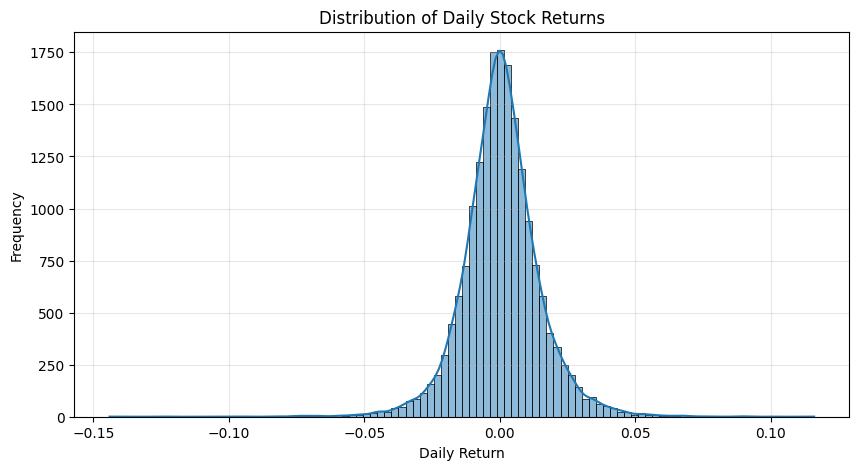

In [63]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=eda_data,
    x="Daily_Return",
    bins=100,
    kde=True
)

plt.title("Distribution of Daily Stock Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

# Interpretation
The histogram shows that daily stock returns are heavily concentrated around zero, indicating that most stocks experienced relatively small daily price movements. The distribution has a sharp peak near zero, with the frequency of returns decreasing as movements become larger. However, a few extreme positive and negative returns are also observed, indicating occasional significant market fluctuations. The distribution has relatively long tails, suggesting that unusually large price movements occur, although less frequently. Overall, this highlights the presence of both normal daily fluctuations and occasional extreme movements in the selected stocks, which are important when assessing stock market risk.

Chart 2 – Distribution of 20-Day Historical Volatility
Purpose: To understand how daily stock volatility is distributed across the 15 selected companies. This helps identify whether most observations show low volatility or whether periods of higher market risk are also common.

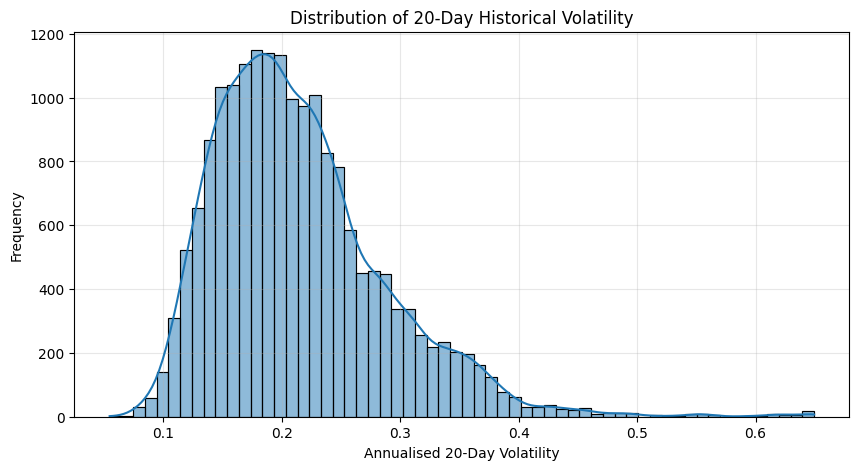

In [64]:
eda_data = cleaned_data.copy()
plt.figure(figsize=(10,5))

sns.histplot(
    data=eda_data,
    x="Volatility_20",
    bins=60,
    kde=True
)

plt.title("Distribution of 20-Day Historical Volatility")
plt.xlabel("Annualised 20-Day Volatility")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

# Interpretation
The histogram shows that most observations of annualised 20-day historical volatility are concentrated between approximately 0.12 and 0.27, with the highest frequency around 0.17–0.20. The distribution is positively skewed, with a long tail extending towards higher volatility values. This indicates that most observations experienced relatively moderate volatility, while a smaller number experienced significantly higher market fluctuations. A few observations also extend beyond 0.50, highlighting periods of unusually high volatility. Overall, the chart demonstrates that stock market risk varies over time, with occasional periods of elevated volatility.

Chart 3 – Distribution of 60-Day Historical Volatility
Purpose: To understand volatility over a longer period and examine how stock market fluctuations behave across a 60-trading-day window.

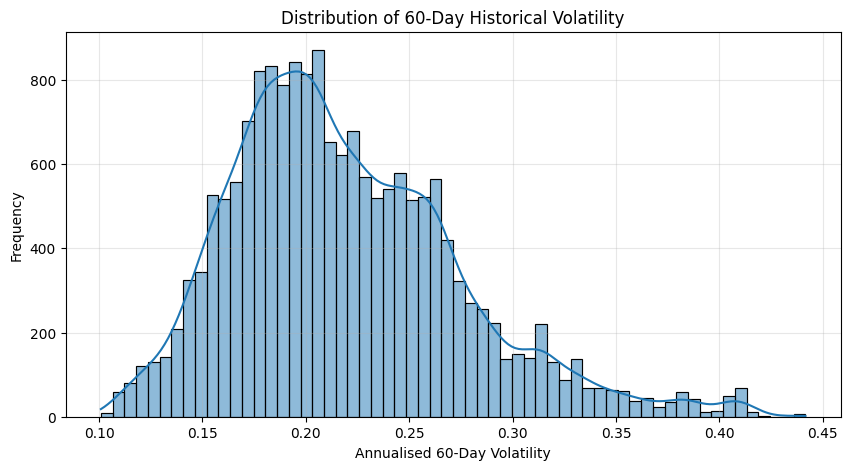

In [65]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=eda_data,
    x="Volatility_60",
    bins=60,
    kde=True
)

plt.title("Distribution of 60-Day Historical Volatility")
plt.xlabel("Annualised 60-Day Volatility")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

# Interpretation
The histogram shows that most observations of annualised 60-day historical volatility are concentrated between approximately 0.15 and 0.27, with the highest frequency around 0.18–0.21. The distribution is positively skewed, with a gradual decline in frequency as volatility increases. A smaller number of observations extend beyond 0.30, indicating periods of relatively high market fluctuations. Compared with the 20-day volatility distribution, the 60-day volatility distribution appears smoother and less spread towards extreme values. This suggests that a longer observation window captures more sustained volatility patterns and reduces the influence of short-term fluctuations.

Chart 4 – Correlation Heatmap of Financial Variables
Purpose: To examine the relationships between financial variables and identify which variables move together. This helps us understand potential relationships between stock returns, volatility, prices and trading volume.

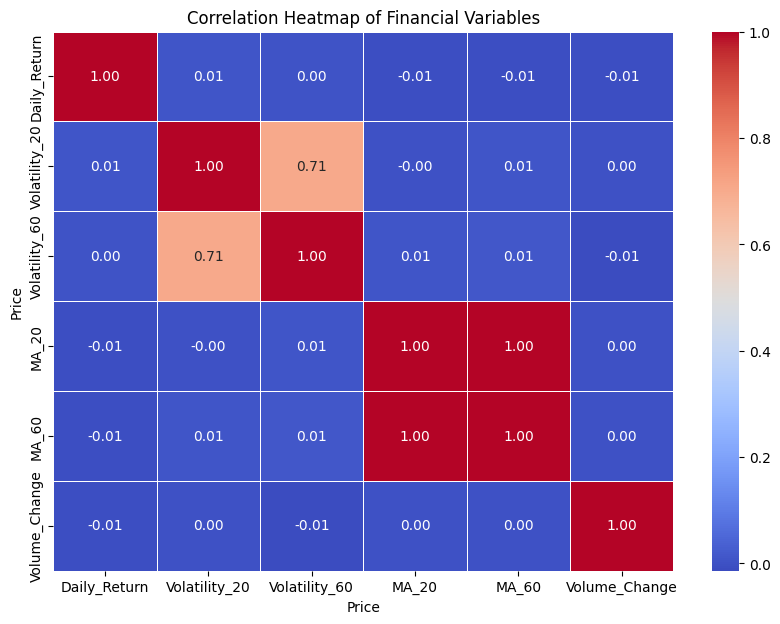

In [66]:
correlation_columns = [
    "Daily_Return",
    "Volatility_20",
    "Volatility_60",
    "MA_20",
    "MA_60",
    "Volume_Change"
]

correlation_matrix = eda_data[correlation_columns].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Financial Variables")
plt.show()

# Interpretation
The correlation heatmap highlights the relationships between the selected financial variables. The strongest positive relationship is observed between 20-day and 60-day volatility, with a correlation of 0.71, indicating that stocks experiencing higher short-term volatility generally also tend to experience higher long-term volatility.

The 20-day and 60-day moving averages show an almost perfect positive correlation of 1.00, as both indicators are calculated using the same stock price series over different time periods. The remaining variables, including daily returns and volume changes, show very weak correlations with most other variables.

Overall, the heatmap indicates that volatility measures are meaningfully related, while most other pairs have weak linear relationships. This highlights the importance of volatility as a factor in assessing stock market risk.

Chart 5 – Average Volatility by Stock
Purpose: To compare the average 20-day historical volatility across the 15 selected companies and identify which stocks have experienced relatively higher or lower volatility during the study period.

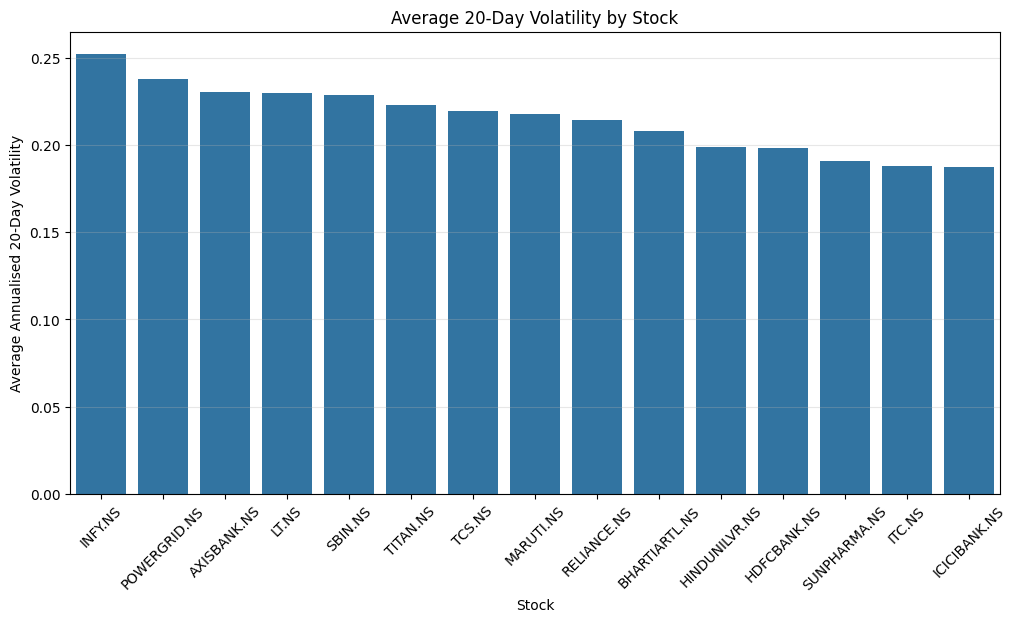

In [67]:
stock_volatility = (
    eda_data.groupby("Stock")["Volatility_20"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=stock_volatility,
    x="Stock",
    y="Volatility_20"
)

plt.title("Average 20-Day Volatility by Stock")
plt.xlabel("Stock")
plt.ylabel("Average Annualised 20-Day Volatility")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

# Interpretation
The bar chart compares the average annualised 20-day historical volatility across the 15 selected companies. Infosys (INFY.NS) records the highest average volatility at approximately 25%, followed by Power Grid (POWERGRID.NS) and Axis Bank (AXISBANK.NS), at around 23%. On the other hand, ICICI Bank (ICICIBANK.NS), ITC (ITC.NS) and Sun Pharma (SUNPHARMA.NS) show relatively lower average volatility, at approximately 19%.

The chart indicates that volatility levels differ across companies, suggesting that some stocks experience greater price fluctuations than others. This comparison helps investors and portfolio managers identify relatively higher- and lower-volatility stocks when assessing portfolio risk.

### Overall EDA Findings

The exploratory data analysis of the 15 selected NSE-listed companies reveals several important patterns in stock market behaviour:

1. Daily stock returns are concentrated around zero, although occasional extreme positive and negative movements are observed.
2. The 20-day and 60-day volatility distributions show that most observations experience moderate volatility, with a smaller number of periods showing significantly higher volatility.
3. The correlation heatmap identifies a strong positive relationship between 20-day and 60-day volatility, highlighting the importance of volatility measures in understanding stock risk.
4. The average volatility comparison shows differences across companies, with Infosys recording the highest average 20-day volatility and ICICI Bank recording the lowest.
5. Overall, the analysis indicates that stock market risk varies across both time periods and companies. Historical volatility is therefore an important factor to consider when assessing and classifying stock risk.

### Verification of the Saved Machine Learning Model

After saving the final Random Forest model using the Joblib library, a verification process was performed to ensure that the saved model could be loaded and used independently for predictions.

The verification involved loading the saved `.pkl` model bundle, checking the stored model details and input features, and generating a sample prediction using an observation from the testing dataset.

The model was also tested for its ability to generate probability scores for all three risk categories: Low, Medium and High.

This process was conducted to confirm that the saved model was functioning correctly and was suitable for integration into the Streamlit application.

The following steps were performed:

1. Load the saved Random Forest model bundle using Joblib.
2. Verify the model name, input features and risk categories.
3. Select one observation from the testing dataset.
4. Generate a risk category prediction using the loaded model.
5. Generate probability scores for the three risk categories.
6. Verify that the model produces a valid prediction and probability output.

In [68]:
import joblib
import os

# Step 1: Verify that the saved file exists
model_path = "/content/stock_risk_random_forest_bundle.pkl"

assert os.path.exists(model_path), "Model file not found!"

# Step 2: Load the saved model bundle
loaded_bundle = joblib.load(model_path)

print("Model loaded successfully!")

# Step 3: Verify model details
print("\nModel Name:", loaded_bundle["model_name"])
print("Input Features:", loaded_bundle["feature_columns"])
print("Risk Categories:", loaded_bundle["risk_categories"])

# Step 4: Select one observation from testing data
sample_input = X_test.iloc[[0]]

# Step 5: Generate prediction
loaded_model = loaded_bundle["model"]

prediction = loaded_model.predict(sample_input)

# Step 6: Generate prediction probabilities
probabilities = loaded_model.predict_proba(sample_input)

print("\nPredicted Risk Category:", prediction[0])

print("\nPrediction Probabilities:")

# Use the model's actual class order for correct probability mapping
for category, probability in zip(
    loaded_model.classes_,
    probabilities[0]
):
    print(f"{category}: {probability:.2%}")

# Step 7: Final verification
assert len(loaded_bundle["feature_columns"]) == 6
assert len(prediction) == 1
assert len(probabilities[0]) == 3
assert abs(probabilities[0].sum() - 1) < 0.000001

print("\nAll model verification checks passed!")

Model loaded successfully!

Model Name: Random Forest
Input Features: ['Daily_Return', 'Volatility_20', 'Volatility_60', 'Price_to_MA20', 'Price_to_MA60', 'Log_Volume_Change']
Risk Categories: ['Low', 'Medium', 'High']

Predicted Risk Category: Medium

Prediction Probabilities:
High: 19.38%
Low: 38.93%
Medium: 41.69%

All model verification checks passed!


The verification process successfully confirmed that the saved Random Forest model could be loaded using the Joblib library. The model details, six input features and three risk categories were verified.

A sample observation from the testing dataset was provided to the loaded model. The model predicted the observation as Medium Risk, with a probability of 41.69%. The probabilities for Low and High risk were 38.93% and 19.38%, respectively.

The probability scores totalled 100%, and all model verification checks were successfully completed. This confirms that the saved model can generate predictions without requiring retraining and is technically ready for integration into the Streamlit application.